# 0) Modul importe

In [24]:
%pip install ICIW_Plots
%pip install cma
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import pandas as pd
import glob
from scipy.constants import R
from scipy.integrate import solve_ivp
from scipy.signal import correlate, correlation_lags
from pathlib import Path
import sys
import inspect


from AZA_THB_solver import *
from AZA_THB_tools import *
from AZA_THB_reactor_input import *
from AZA_THB_reactor_output import *
from AZA_THB_optimizer import Optimizer

if 'ICIWstyle' in plt.style.available:
    plt.style.use('ICIWstyle')

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.




[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# 1) Importe Daten

In [25]:
# Auswertung Experiment
path_data_exp = np.load(r"Data files\exp_data_evaluation_gessys_reac_250nml-min_matrix_250nml_min_2bar_150grad.npy", allow_pickle=True)


# nRTDs
#path_nRTDs = np.load(r"Data files\Run_2026-07-29_113631_2bar_150grad_250nml-min.npy", allow_pickle=True).item()
path_nRTDs = np.load(r"Data files\Run_2026-07-30_090759_2bar_150grad_250nml-min_caphsa_reope.npy", allow_pickle=True).item()
path_nRTDs_ref = np.load(r"Data files\Run_2026-07-29_123209_2bar_150grad_250nml-min_reope.npy", allow_pickle=True).item()

# optimized system
path_opti_sys = np.load(r"C:\Users\admin\Documents\GitHub\THA\Experiments\THB_002\Optimization Results\ 31-07-2026_2bar_150grad_caphsa_validierung.npy", allow_pickle=True).item()
path_opti_sys_ref = np.load(r"C:\Users\admin\Documents\GitHub\THA\Experiments\THB_002\Optimization Results\ 28-07-2026_2bar_150grad_validierung.npy", allow_pickle=True).item()

In [26]:
# Dateien laden und extrahieren

Ar = 0

# aktuelles Experiment 
t_lin          = path_data_exp.item().get('t_lin')
#ni_out_cycle   = path_data_exp.item().get('ni_out_cycle')
ni_out_cycle = path_opti_sys.get('ni_out_cycle')
ni_trans_cycle = path_data_exp.item().get('ni_trans_cycle')
ni_RTD_cycle   = path_data_exp.item().get('ni_RTD_cycle')
C_balance      = path_data_exp.item().get('C_balance')
O_balance      = path_data_exp.item().get('O_balance')

#  nRTDs 
CNN_ts = path_nRTDs.get('ts')
CNN_Es = path_nRTDs.get('Es')
t_pred_total = path_nRTDs.get('t_pred total')
y_pred_total = path_nRTDs.get('y_pred total')

# nRTDs Referenz
CNN_ts_ref = path_nRTDs_ref.get('ts')
CNN_Es_ref = path_nRTDs_ref.get('Es')

#optimiertes System 
t_lin_opti          = path_opti_sys.get('t_lin')
ni_trans_cycle_opti  = path_opti_sys.get('ni_trans_cycle')
ni_out_cycle_opti    = path_opti_sys.get('ni_out_cycle')
ni_RTD_cycle_opti    = path_opti_sys.get('ni_RTD_cycle')
n_dot_trans_int_opti = path_opti_sys.get('n_dot_trans_int')
n_dot_theo_int_opti  = path_opti_sys.get('n_dot_theo_int')
n_dot_i_int_opti     = path_opti_sys.get('n_dot_i_int')
theta_s_opti         = path_opti_sys.get('theta_s')
theta_x_opti         = path_opti_sys.get('theta_x')

# optimiertes System Referenz
t_lin_ref          = path_opti_sys_ref.get('t_lin')
ni_trans_cycle_ref  = path_opti_sys_ref.get('ni_trans_cycle')
ni_out_cycle_ref    = path_opti_sys_ref.get('ni_out_cycle')
ni_RTD_cycle_ref    = path_opti_sys_ref.get('ni_RTD_cycle')
n_dot_trans_int_ref = path_opti_sys_ref.get('n_dot_trans_int')
n_dot_theo_int_ref  = path_opti_sys_ref.get('n_dot_theo_int')
n_dot_i_int_ref     = path_opti_sys_ref.get('n_dot_i_int')
theta_s_ref         = path_opti_sys_ref.get('theta_s')
theta_x_ref         = path_opti_sys_ref.get('theta_x')


# Vergleich Model mit Referenz

Geschätzter Offset (Referenz): +0.000 s
Geschätzter Offset (aktuell):  +0.000 s


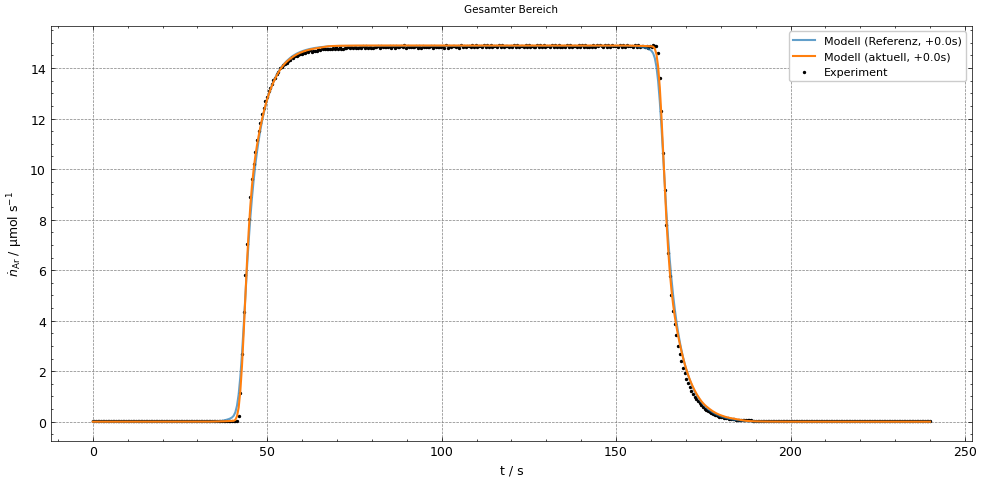

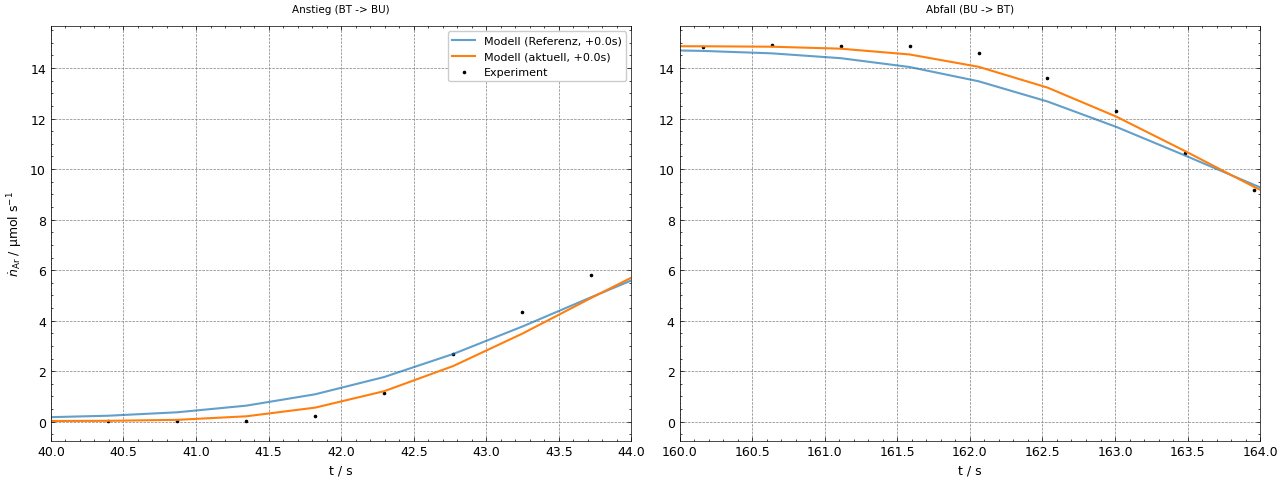

In [27]:
Ar = 0

dt_lin = t_lin[1] - t_lin[0]

# --- beide Modell-Ergebnisse auf das Zeitgitter des Experiments (t_lin) bringen ---
if len(t_lin_opti) != len(t_lin) or not np.allclose(t_lin_opti, t_lin):
    n_dot_i_int_opti_on_grid = interpolation_function(t_lin, t_lin_opti, n_dot_i_int_opti)
else:
    n_dot_i_int_opti_on_grid = n_dot_i_int_opti

if len(t_lin_ref) != len(t_lin) or not np.allclose(t_lin_ref, t_lin):
    n_dot_i_int_ref_on_grid = interpolation_function(t_lin, t_lin_ref, n_dot_i_int_ref)
else:
    n_dot_i_int_ref_on_grid = n_dot_i_int_ref

def estimate_offset(t, model, exp, t_min=None, t_max=None):
    """Schätzt den wahrscheinlichsten Zeitversatz zwischen Modell und
    Experiment per Kreuzkorrelation. Positiv = Modell muss nach rechts
    (später) verschoben werden, um zum Experiment zu passen."""
    dt = t[1] - t[0]
    mask = np.ones_like(t, dtype=bool) if t_min is None else (t > t_min) & (t < t_max)
    m = model[mask] - model[mask].mean()
    e = exp[mask] - exp[mask].mean()
    corr = correlate(e, m, mode='full')
    lags = correlation_lags(len(e), len(m), mode='full') * dt
    return lags[np.argmax(corr)]

offset_ref  = estimate_offset(t_lin, n_dot_i_int_ref_on_grid[Ar], ni_out_cycle[Ar], t_min=20, t_max=220)
offset_opti = estimate_offset(t_lin, n_dot_i_int_opti_on_grid[Ar], ni_out_cycle[Ar], t_min=20, t_max=220)

print(f"Geschätzter Offset (Referenz): {offset_ref:+.3f} s")
print(f"Geschätzter Offset (aktuell):  {offset_opti:+.3f} s")

#  Offsets in Sekunden) 
offset_ref  = 0  # Verschiebung Modell (Referenz)
offset_opti = 0#-49 # Verschiebung Modell (aktuell)

# --- manuelle Offsets anwenden (zyklische Verschiebung, passend zum
#     periodischen Signal -- kein Rand-/Extrapolationsartefakt) ---
shift_ref_idx  = int(round(offset_ref / dt_lin))
shift_opti_idx = int(round(offset_opti / dt_lin))

n_dot_i_int_ref_shifted  = np.roll(n_dot_i_int_ref_on_grid, shift_ref_idx, axis=-1)
n_dot_i_int_opti_shifted = np.roll(n_dot_i_int_opti_on_grid, shift_opti_idx, axis=-1)

# --- Gesamter Bereich ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t_lin, n_dot_i_int_ref_shifted[Ar] * 1e6, label=f'Modell (Referenz, {offset_ref:+.1f}s)', color='tab:blue', alpha=0.7)
ax.plot(t_lin, n_dot_i_int_opti_shifted[Ar] * 1e6, label=f'Modell (aktuell, {offset_opti:+.1f}s)', color='tab:orange')
ax.scatter(t_lin, ni_out_cycle[Ar] * 1e6, label='Experiment', color='black', marker='.', s=8)
ax.set_title('Gesamter Bereich')
ax.set_xlabel('t / s'); ax.set_ylabel(r'$\dot{n}_\mathrm{Ar}$ / µmol s$^{-1}$')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- Zoom-Plots: Anstieg / Abfall ---
def zoom_plot(ax, x1, x2, title):
    ax.plot(t_lin, n_dot_i_int_ref_shifted[Ar] * 1e6, label=f'Modell (Referenz, {offset_ref:+.1f}s)', color='tab:blue', alpha=0.7)
    ax.plot(t_lin, n_dot_i_int_opti_shifted[Ar] * 1e6, label=f'Modell (aktuell, {offset_opti:+.1f}s)', color='tab:orange')
    ax.scatter(t_lin, ni_out_cycle[Ar] * 1e6, label='Experiment', color='black', marker='.', s=10)
    ax.set_xlim(x1, x2)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

zoom_plot(axes[0], 40, 44, 'Anstieg (BT -> BU)')
zoom_plot(axes[1], 160, 164, 'Abfall (BU -> BT)')

axes[0].set_ylabel(r'$\dot{n}_\mathrm{Ar}$ / µmol s$^{-1}$')
axes[0].set_xlabel('t / s'); axes[1].set_xlabel('t / s')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Molenbruch nach jeder E funktion

In [28]:
# =====================================================================
# Kaskade E2, E2⊗E3, E2⊗E3⊗E4 -- angewendet auf 'x_out inlet' (Rohdaten),
# verglichen mit dem vollständigen Modellergebnis n_dot_i_int_opti
# =====================================================================

Ar = 0

t_1, t_2, t_3, t_4 = CNN_ts[0], CNN_ts[1], CNN_ts[2], CNN_ts[3]
E_1, E_2, E_3, E_4 = CNN_Es[0], CNN_Es[1], CNN_Es[2], CNN_Es[3]
dt = t_2[1] - t_2[0]

def normalize_kernel(t, E):
    return E / np.trapezoid(E, t)

def padding_function_E(kernel_t, signal):
    """Nachbau von Output.padding_function(type='E'): Null-Padding an
    beiden Seiten, Laenge len(kernel_t)-1."""
    pad_len = len(kernel_t) - 1
    return np.hstack((np.zeros(pad_len), signal, np.zeros(pad_len)))

def convolve_kernels(t_a, E_a, t_b, E_b, dt):
    E_b_padded = padding_function_E(t_a, E_b)
    t_ab = np.linspace(0, t_a[-1] + t_b[-1], E_a.size + E_b.size - 1)
    E_ab = np.convolve(E_a, E_b_padded, mode='valid') * dt
    return t_ab, E_ab

def chain_convolve(kernel_list, dt):
    t_c, E_c = kernel_list[0]
    E_c = normalize_kernel(t_c, E_c)
    for t_i, E_i in kernel_list[1:]:
        t_c, E_c = convolve_kernels(t_c, E_c, t_i, normalize_kernel(t_i, E_i), dt)
        E_c = normalize_kernel(t_c, E_c)
    return t_c, E_c

def reconstruct_raw_step(x_i_RTD):
    """Gemittelte Ar-Sprungantwort aus rohen x_i_RTD-Daten (4er-Interleave-Muster)."""
    n_periods = x_i_RTD.shape[0] // 4
    x_bu, x_bt = [], []
    for i in range(n_periods):
        x_bu.append(x_i_RTD[4*i, 0, ...])
        x_bt.append(x_i_RTD[2 + 4*i, 0, ...])
    return np.hstack((np.average(x_bu, axis=0), np.average(x_bt, axis=0)[1:]))

def apply_kernel_to_signal(t_kernel, E_kernel, x_one_period, n_period_points, n_repeats=5):
    """Faltet ein periodisch wiederholtes Signal mit einem Kernel und schneidet
    den eingeschwungenen mittleren Zyklus heraus."""
    x_repeated = np.tile(x_one_period, n_repeats)
    dt_local = t_kernel[1] - t_kernel[0]
    t_k_grid = np.arange(0, t_kernel[-1], dt_local)
    E_k_grid = np.interp(t_k_grid, t_kernel, E_kernel)
    E_k_grid /= np.trapezoid(E_k_grid, t_k_grid)
    response = np.convolve(x_repeated, E_k_grid, mode='full')[: len(x_repeated)] * dt_local
    middle_start = (n_repeats // 2) * n_period_points
    return response[middle_start: middle_start + n_period_points]

# --- Eingangssignal: rohe 'x_out inlet'-Daten rekonstruieren ---
x_inlet_raw = reconstruct_raw_step(path_nRTDs.get('x_out inlet'))
n_period_points = x_inlet_raw.size
t_inlet_grid = np.linspace(0, 240, n_period_points)

# --- Kaskade: E2, E2⊗E3, E2⊗E3⊗E4 ---
t_2n, E_2n = t_2, normalize_kernel(t_2, E_2)
t_23n, E_23n = chain_convolve([(t_2, E_2), (t_3, E_3)], dt)
t_234n, E_234n = chain_convolve([(t_2, E_2), (t_3, E_3), (t_4, E_4)], dt)

resp_E2   = apply_kernel_to_signal(t_2n, E_2n, x_inlet_raw, n_period_points)
resp_E23  = apply_kernel_to_signal(t_23n, E_23n, x_inlet_raw, n_period_points)
resp_E234 = apply_kernel_to_signal(t_234n, E_234n, x_inlet_raw, n_period_points)

# --- auf t_lin bringen, um mit n_dot_i_int_opti zu vergleichen ---
x_inlet_on_tlin = np.interp(t_lin, t_inlet_grid, x_inlet_raw)
resp_E2_on_tlin   = np.interp(t_lin, t_inlet_grid, resp_E2)
resp_E23_on_tlin  = np.interp(t_lin, t_inlet_grid, resp_E23)
resp_E234_on_tlin = np.interp(t_lin, t_inlet_grid, resp_E234)

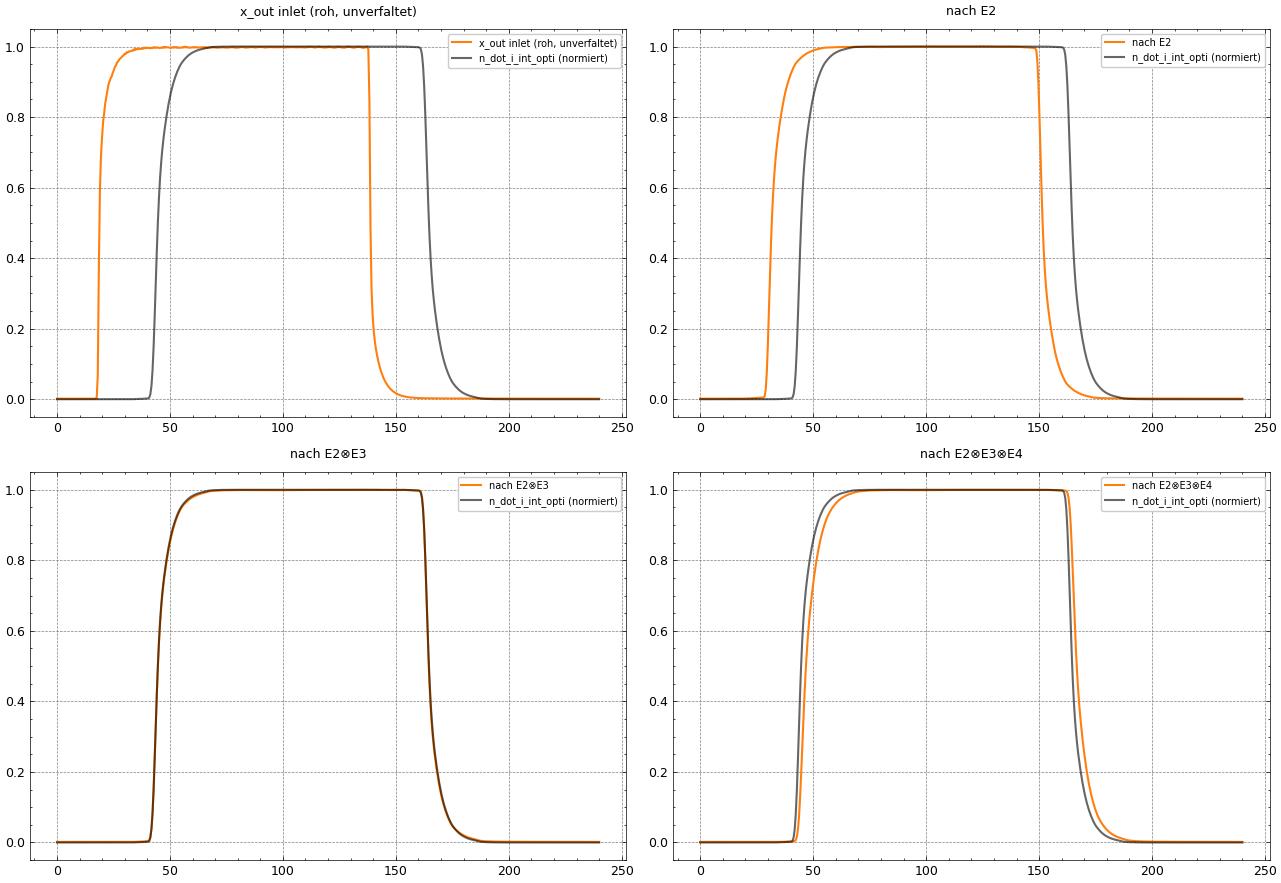

In [29]:
# =====================================================================
# Plot: Kaskaden-Stufen (normiert, da x_out inlet nicht in µmol/s
# skaliert ist) vs. das vollständige Modellergebnis (ebenfalls normiert)
# =====================================================================

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

n_dot_opti_norm = n_dot_i_int_opti[Ar] / n_dot_i_int_opti[Ar].max()

stages_plot = [
    ("x_out inlet (roh, unverfaltet)", x_inlet_on_tlin / x_inlet_on_tlin.max()),
    ("nach E2", resp_E2_on_tlin / resp_E2_on_tlin.max()),
    ("nach E2⊗E3", resp_E23_on_tlin / resp_E23_on_tlin.max()),
    ("nach E2⊗E3⊗E4", resp_E234_on_tlin / resp_E234_on_tlin.max()),
]

for ax, (title, sig) in zip(axes.flat, stages_plot):
    ax.plot(t_lin, sig, label=title, color='tab:orange')
    ax.plot(t_lin, n_dot_opti_norm, label='n_dot_i_int_opti (normiert)', color='black', alpha=0.6)
    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

# Vergleich Model mit E-Kaskade

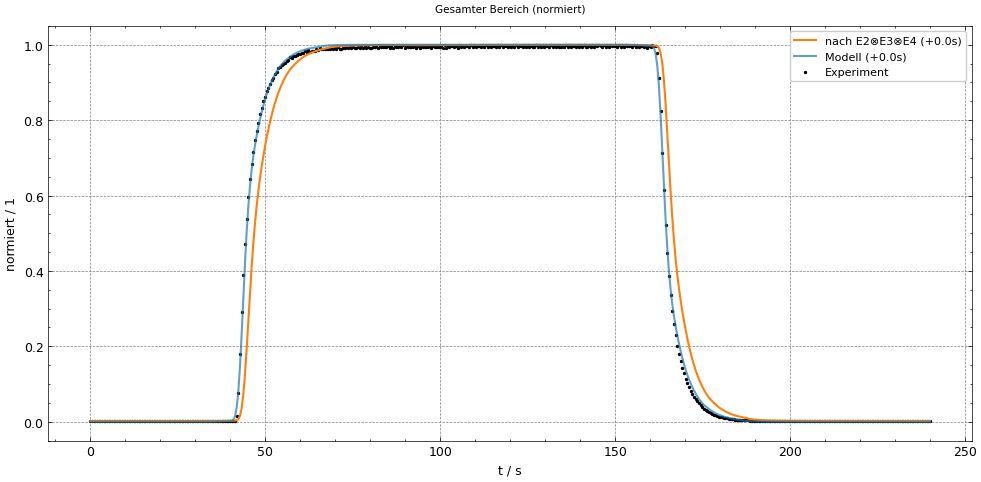

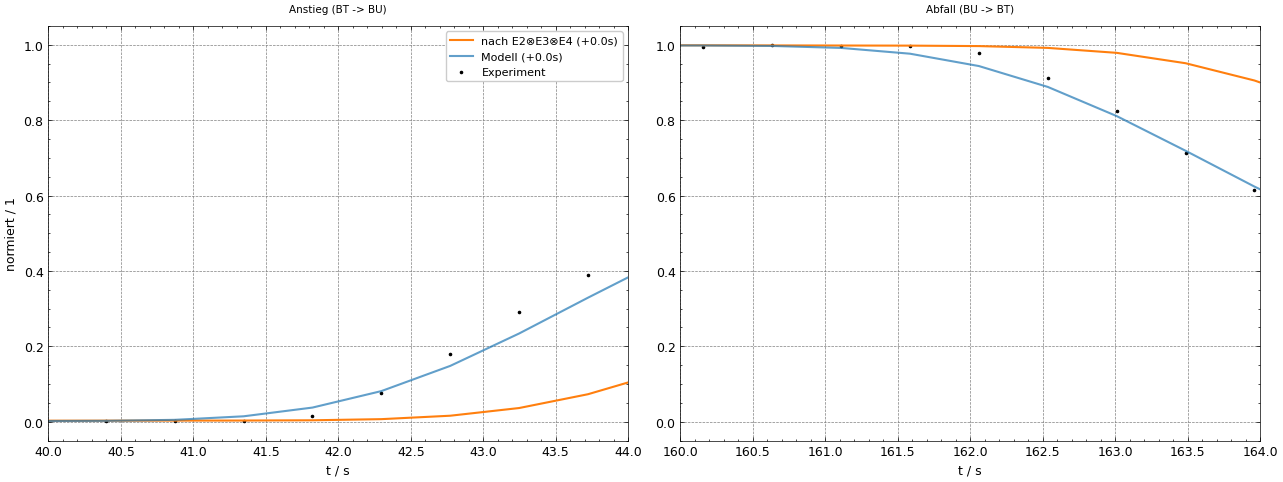

In [30]:
# =====================================================================
# Kaskaden-Endstufe (E2⊗E3⊗E4) vs. Modell vs. Experiment -- mit manuell
# einstellbarem Zeitversatz je Kurve, Gesamtbereich + zwei Zoom-Plots
# =====================================================================

Ar = 0

# --- HIER Offsets von Hand anpassen (in Sekunden) ---
offset_chain = 0  # Verschiebung Kaskade (E2⊗E3⊗E4 auf x_out inlet)
offset_model = 0   # Verschiebung Modell (n_dot_i_int_opti)
# -----------------------------------------------------

dt_lin = t_lin[1] - t_lin[0]

n_dot_opti_norm = n_dot_i_int_opti[Ar] / n_dot_i_int_opti[Ar].max()
ni_out_norm = ni_out_cycle[Ar] / ni_out_cycle[Ar].max()
chain_norm = resp_E234_on_tlin / resp_E234_on_tlin.max()

shift_chain_idx = int(round(offset_chain / dt_lin))
shift_model_idx = int(round(offset_model / dt_lin))

chain_shifted = np.roll(chain_norm, shift_chain_idx)
model_shifted = np.roll(n_dot_opti_norm, shift_model_idx)

# --- Gesamter Bereich ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t_lin, chain_shifted, label=f'nach E2⊗E3⊗E4 ({offset_chain:+.1f}s)', color='tab:orange')
ax.plot(t_lin, model_shifted, label=f'Modell ({offset_model:+.1f}s)', color='tab:blue', alpha=0.7)
ax.scatter(t_lin, ni_out_norm, label='Experiment', color='black', marker='.', s=8)
ax.set_title('Gesamter Bereich (normiert)')
ax.set_xlabel('t / s'); ax.set_ylabel('normiert / 1')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- Zoom-Plots: Anstieg / Abfall ---
def zoom_plot(ax, x1, x2, title):
    ax.plot(t_lin, chain_shifted, label=f'nach E2⊗E3⊗E4 ({offset_chain:+.1f}s)', color='tab:orange')
    ax.plot(t_lin, model_shifted, label=f'Modell ({offset_model:+.1f}s)', color='tab:blue', alpha=0.7)
    ax.scatter(t_lin, ni_out_norm, label='Experiment', color='black', marker='.', s=10)
    ax.set_xlim(x1, x2)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

zoom_plot(axes[0], 40, 44, 'Anstieg (BT -> BU)')
zoom_plot(axes[1], 160, 164, 'Abfall (BU -> BT)')

axes[0].set_ylabel('normiert / 1')
axes[0].set_xlabel('t / s'); axes[1].set_xlabel('t / s')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Vergleich Model und Rückoperation 

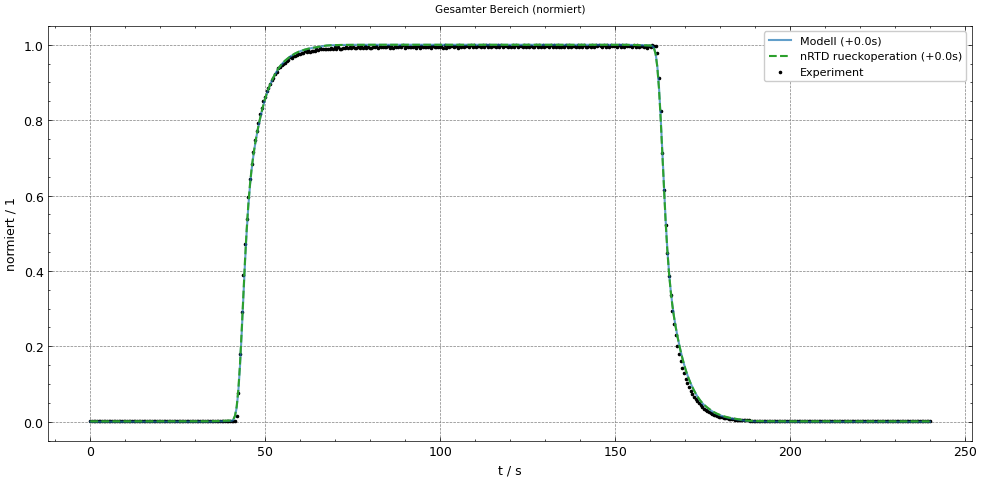

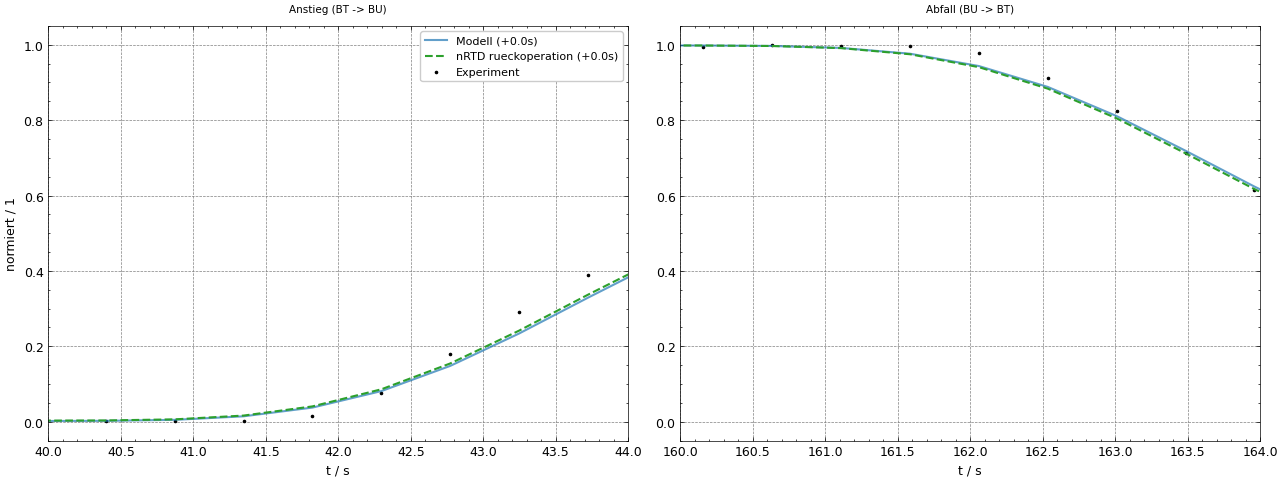

In [31]:
# =====================================================================
# y_pred total ist Selbstkonsistenz des Netzes bestätigt (t_pred_total
# fuer alle 20 Laeufe identisch) -- jetzt der Vergleichsplot:
# Modell, eigene Kette E2⊗E3⊗E4, y_pred total, Experiment
# =====================================================================

Ar = 0
offset_model = 0   # Verschiebung Modell (n_dot_i_int_opti)
offset_pred  = 0   # Verschiebung y_pred total (Netz-Selbstkonsistenz)
# Rueckoperation des Netzes: Ar-Halbperioden zu einem 240-s-Zyklus zusammensetzen
# (Laufmuster wie in Reactor_input: 4i = Ar auf, 2+4i = Ar ab)
n_pred = y_pred_total.shape[0] // 4
y_pred_bu = np.average([y_pred_total[4 * i, 0]     for i in range(n_pred)], axis=0)
y_pred_bt = np.average([y_pred_total[2 + 4 * i, 0] for i in range(n_pred)], axis=0)

y_pred_cycle = np.hstack((y_pred_bu, y_pred_bt[1:]))          # 961 Punkte, dt = 0.25 s
t_pred_cycle = np.linspace(0, 240, y_pred_cycle.size)

y_pred_on_tlin = np.interp(t_lin, t_pred_cycle, y_pred_cycle)
y_pred_norm = y_pred_on_tlin / y_pred_on_tlin.max()

dt_lin = t_lin[1] - t_lin[0]

n_dot_opti_norm = n_dot_i_int_opti[Ar] / n_dot_i_int_opti[Ar].max()
ni_out_norm = ni_out_cycle[Ar] / ni_out_cycle[Ar].max()
chain_norm = resp_E234_on_tlin / resp_E234_on_tlin.max()

shift_chain_idx = int(round(offset_chain / dt_lin))
shift_model_idx = int(round(offset_model / dt_lin))
shift_pred_idx  = int(round(offset_pred / dt_lin))

chain_shifted = np.roll(chain_norm, shift_chain_idx)
model_shifted = np.roll(n_dot_opti_norm, shift_model_idx)
pred_shifted  = np.roll(y_pred_norm, shift_pred_idx)

def make_plot(ax, x1=None, x2=None, title=""):
    ax.plot(t_lin, model_shifted, label=f'Modell ({offset_model:+.1f}s)', color='tab:blue', alpha=0.7)
    ax.plot(t_lin, pred_shifted, label=f'nRTD rueckoperation ({offset_pred:+.1f}s)', color='tab:green', linestyle='--')
    ax.scatter(t_lin, ni_out_norm, label='Experiment', color='black', marker='.', s=10)
    if x1 is not None:
        ax.set_xlim(x1, x2)
    ax.set_title(title)

# --- Gesamter Bereich ---
fig, ax = plt.subplots(figsize=(10, 5))
make_plot(ax, title='Gesamter Bereich (normiert)')
ax.set_xlabel('t / s'); ax.set_ylabel('normiert / 1')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- Zoom-Plots: Anstieg / Abfall ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
make_plot(axes[0], 40, 44, 'Anstieg (BT -> BU)')
make_plot(axes[1], 160, 164, 'Abfall (BU -> BT)')
axes[0].set_ylabel('normiert / 1')
axes[0].set_xlabel('t / s'); axes[1].set_xlabel('t / s')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()



# Messwerte

Anteil als 'dynamisch' markierter Punkte: 13.8%


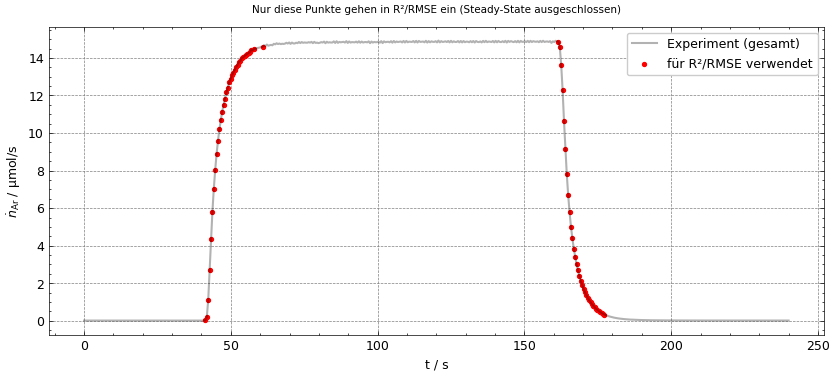

In [32]:
def get_transient_mask(t, y_exp, threshold_frac=0.02):
    """Markiert automatisch die dynamischen (Flanken-)Bereiche des Signals --
    Punkte mit spürbarer zeitlicher Änderung -- und schließt den (fast
    konstanten) Steady-State aus. Basiert auf der Steigung des EXPERIMENTS
    (Referenzsignal), nicht des Modells, damit die Maske unabhängig davon
    ist, welches Modell gerade geprüft wird."""
    dy_dt = np.gradient(y_exp, t)
    threshold = threshold_frac * np.max(np.abs(dy_dt))
    return np.abs(dy_dt) > threshold

transient_mask = get_transient_mask(t_lin, ni_out_cycle[Ar])
print(f"Anteil als 'dynamisch' markierter Punkte: {transient_mask.mean()*100:.1f}%")

# zur Kontrolle visualisieren, welche Punkte tatsächlich einbezogen werden
plt.figure(figsize=(10, 4))
plt.plot(t_lin, ni_out_cycle[Ar] * 1e6, color='black', alpha=0.3, label='Experiment (gesamt)')
plt.scatter(t_lin[transient_mask], ni_out_cycle[Ar, transient_mask] * 1e6, color='red', s=8, label='für R²/RMSE verwendet')
plt.legend(); plt.xlabel('t / s'); plt.ylabel(r'$\dot{n}_\mathrm{Ar}$ / µmol/s')
plt.title('Nur diese Punkte gehen in R²/RMSE ein (Steady-State ausgeschlossen)')
plt.show()

def r_squared(exp, model, mask):
    e, m = exp[mask], model[mask]
    ss_res = np.sum((e - m) ** 2)
    ss_tot = np.sum((e - e.mean()) ** 2)
    return 1 - ss_res / ss_tot

def rmse(exp, model, mask):
    return np.sqrt(np.mean((exp[mask] - model[mask]) ** 2))

# jeweils mit dem passenden (verschobenen) Modell rechnen
shift_ref_idx  = int(round(offset_ref  / dt_lin))
shift_opti_idx = int(round(offset_opti / dt_lin))
n_dot_i_int_ref_shifted  = np.roll(n_dot_i_int_ref_on_grid, shift_ref_idx, axis=-1)
n_dot_i_int_opti_shifted = np.roll(n_dot_i_int_opti_on_grid, shift_opti_idx, axis=-1)

r2_ref  = r_squared(ni_out_cycle[Ar], n_dot_i_int_ref_shifted[Ar], transient_mask)
r2_opti = r_squared(ni_out_cycle[Ar], n_dot_i_int_opti_shifted[Ar], transient_mask)
rmse_ref  = rmse(ni_out_cycle[Ar], n_dot_i_int_ref_shifted[Ar], transient_mask)
rmse_opti = rmse(ni_out_cycle[Ar], n_dot_i_int_opti_shifted[Ar], transient_mask)



In [33]:
# ---------------------------------------------------------------- Guetemasse
def flank_mask(y, rel_thresh=0.02):
    """Punkte, an denen sich das Signal nennenswert aendert (~14 % der Periode)."""
    g = np.abs(np.gradient(y, t_lin))
    return g > rel_thresh * g.max()

def flank_stats(t, y, i_centre, half_width_s=30.0, rising=True):
    """t50 und 10-90-Breite einer einzelnen Flanke."""
    w = int(round(half_width_s / (t[1] - t[0])))
    i0, i1 = max(0, i_centre - w), min(y.size, i_centre + w)
    seg, tt = y[i0:i1], t[i0:i1]
    z = (seg - seg.min()) / (seg.max() - seg.min())
    if not rising:
        z = 1 - z
    def cross(f):
        j = int(np.argmax(z > f))
        return np.interp(f, [z[j-1], z[j]], [tt[j-1], tt[j]])
    return cross(0.5), cross(0.9) - cross(0.1)

def residual_shift(exp, mod):
    """Restversatz, der die Kurve optimal auf das Experiment legt (Kontrolle fuer offset_*)."""
    err = [np.sqrt(np.mean((np.roll(mod, s) - exp)**2)) for s in range(exp.size)]
    s = int(np.argmin(err)) * dt_lin
    return s - 240.0 if s > 120.0 else s

mask = flank_mask(ni_out_norm)
g = np.gradient(ni_out_norm, t_lin)
i_rise, i_fall = int(np.argmax(g)), int(np.argmin(g))

curves = {'Modell': model_shifted, 'nRTD rueckoperation': pred_shifted}
try:
    curves['Kette'] = chain_shifted
except NameError:
    pass

a, b = flank_stats(t_lin, ni_out_norm, i_rise, rising=True)
c, e = flank_stats(t_lin, ni_out_norm, i_fall, rising=False)
print(f'Flankenmaske: {mask.mean()*100:.1f} % der Punkte\n')
print(f'{"":22s} {"R² ges.":>8s} {"R² Flanken":>11s} {"RMSE Flanken":>13s} '
      f'{"Anstieg t50/B":>16s} {"Abfall t50/B":>16s} {"Restversatz":>12s}')
print(f'{"Experiment":22s} {"":>8s} {"":>11s} {"":>13s} '
      f'{a:7.2f} /{b:5.2f} s {c:7.2f} /{e:5.2f} s')

for name, y in curves.items():
    r2   = 1 - np.sum((ni_out_norm - y)**2) / np.sum((ni_out_norm - ni_out_norm.mean())**2)
    r2_f = 1 - np.sum((ni_out_norm[mask] - y[mask])**2) / np.sum((ni_out_norm[mask] - ni_out_norm[mask].mean())**2)
    rmse = np.sqrt(np.mean((ni_out_norm[mask] - y[mask])**2))
    a1, b1 = flank_stats(t_lin, y, i_rise, rising=True)
    a2, b2 = flank_stats(t_lin, y, i_fall, rising=False)
    print(f'{name:22s} {r2:8.4f} {r2_f:11.4f} {rmse:13.5f} '
          f'{a1:7.2f} /{b1:5.2f} s {a2:7.2f} /{b2:5.2f} s {residual_shift(ni_out_norm, y):+9.2f} s')

print(f'\nRMSE ist dimensionslos (normierte Kurven); '
      f'x {ni_out_cycle[Ar].max():.3e} mol/s fuer absolute Werte.')

Flankenmaske: 13.8 % der Punkte

                        R² ges.  R² Flanken  RMSE Flanken    Anstieg t50/B     Abfall t50/B  Restversatz
Experiment                                                  44.38 / 8.83 s  164.58 / 8.05 s
Modell                   0.9997      0.9972       0.01969   44.65 / 9.22 s  164.66 / 9.22 s     +0.00 s
nRTD rueckoperation      0.9997      0.9975       0.01831   44.62 / 9.22 s  164.62 / 9.22 s     +0.00 s
Kette                    0.9828      0.7922       0.16867   46.80 /10.84 s  166.66 /10.40 s     -1.43 s

RMSE ist dimensionslos (normierte Kurven); x 1.492e-05 mol/s fuer absolute Werte.
